# InsightReach — Análisis Exploratorio de Clientes de Restaurantes
## Notebook 1: Limpieza y EDA

**Dataset:** base_datos_restaurantes_USA_v2.csv  
**Ciudad analizada:** Chicago  
**Autor:** Mauricio Melgarejo


## 1. Importación de librerías

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Funciones auxiliares

In [62]:
# Paleta de colores del proyecto
COLOR_PRINCIPAL  = "#2D6A4F"   # verde oscuro — barras principales
COLOR_SECUNDARIO = "#95D5B2"   # verde claro — comparaciones y tortas
COLOR_ACENTO     = "#B7B7B7"   # gris — línea de promedio
COLOR_HIGHLIGHT  = "#1B4332"   # verde muy oscuro — destacados

def graficar_distribucion(df, columna, tipo="bar", titulo="",
                          color=None, mostrar_valores=True,
                          mostrar_promedio=False):
    """
    Genera un grafico de distribucion para una columna.

    Parametros:
        df (DataFrame): dataset a analizar
        columna (str): nombre de la columna a graficar
        tipo (str): tipo de grafico — 'bar', 'pie' o 'hist'
        titulo (str): titulo del grafico
        color (str): color del grafico — usa COLOR_PRINCIPAL por defecto
        mostrar_valores (bool): muestra valores encima de las barras
        mostrar_promedio (bool): muestra linea de promedio en histogramas

    Retorna:
        None
    """
    if color is None:
        color = COLOR_PRINCIPAL

    if tipo == "bar":
        ax = df[columna].value_counts().plot(
            kind="bar",
            figsize=(8, 5),
            color=color
        )
        if mostrar_valores:
            for p in ax.patches:
                ax.annotate(f'{int(p.get_height())}',
                           (p.get_x() + p.get_width()/2, p.get_height()),
                           ha='center', va='bottom', fontsize=9)
        plt.xlabel(columna.replace("_", " ").title())
        plt.ylabel("Cantidad de clientes")
        plt.xticks(rotation=45)

    elif tipo == "pie":
        df[columna].value_counts().plot(
            kind="pie",
            autopct="%1.1f%%",
            figsize=(5, 5),
            colors=[COLOR_PRINCIPAL, COLOR_SECUNDARIO,
                    COLOR_ACENTO, COLOR_HIGHLIGHT]
        )
        plt.ylabel("")

    elif tipo == "hist":
        ax = df[columna].plot(
            kind="hist",
            bins=20,
            figsize=(7, 5),
            color=color
        )
        if mostrar_promedio:
            promedio = df[columna].mean()
            ax.axvline(promedio, color=COLOR_ACENTO,
                      linestyle="--", linewidth=2,
                      label=f'Promedio: {promedio:.1f}')
            ax.legend()
        plt.xlabel(columna.replace("_", " ").title())
        plt.ylabel("Cantidad de clientes")

    plt.title(titulo)
    plt.tight_layout()
    plt.show()

## 2. Carga del dataset

Se carga el archivo CSV con los datos de clientes de InsightReach.

In [63]:
df = pd.read_csv("base_datos_restaurantes_USA_v2.csv")
print(f"Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas")

Dataset cargado: 30000 filas x 17 columnas


## 3. Exploración inicial

In [64]:
display(df.head()) # Primeras 5 filas — ver cómo están organizados los datos

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350


In [65]:
display(df.tail()) # Últimas 5 filas — verificar que el CSV se cargó completo

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
29995,4862097674,Robert,Cortez,20.0,Masculino,Houston,Alto,-3,30.82,Sí,Sí,Vegano,Sí,NaN,garciagregory@example.net,Tarjeta,5781
29996,9458262482,Michael,Holt,78.0,Masculino,Denver,Alto,5,45.04,No,No,Mariscos,No,NaN,jimmy77@example.org,Efectivo,7652
29997,3412365931,Rebecca,Henry,77.0,Femenino,San Diego,Muy Alto,7,93.55,No,Sí,Mariscos,Sí,NaN,NaN,Efectivo,12639
29998,8853079811,Tamara,Griffin,77.0,Femenino,Chicago,Bajo,1,6.18,Sí,No,Otro,No,(243)658-6543x11668,NaN,Tarjeta,1057
29999,4553644223,Tracey,Flynn,57.0,Femenino,Chicago,Bajo,1,6.96,No,Sí,Carnes,No,295.679.7926x321,NaN,Efectivo,1348


In [66]:
# Dimensiones del dataset
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

Filas: 30000
Columnas: 17


In [67]:
df.info() # Tipos de datos y valores no nulos por columna

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  28597 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          14834 non-null  str    
 14  c

In [68]:
display(df.describe().round(2)) # Resumen estadístico por columna numérica

,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.000000e+04,29899.00,30000.00,29855.00,30000.00
mean,5.504765e+09,49.67,3.90,32.60,5389.76
std,2.602799e+09,23.84,2.74,26.40,4538.49
min,1.000153e+09,-5.00,-3.00,0.00,800.00
25%,3.243617e+09,33.00,2.00,13.29,1860.00
50%,5.515865e+09,49.00,4.00,25.51,3402.00
75%,7.754426e+09,65.00,5.00,44.40,7761.00
max,9.999627e+09,300.00,10.00,149.97,17999.00


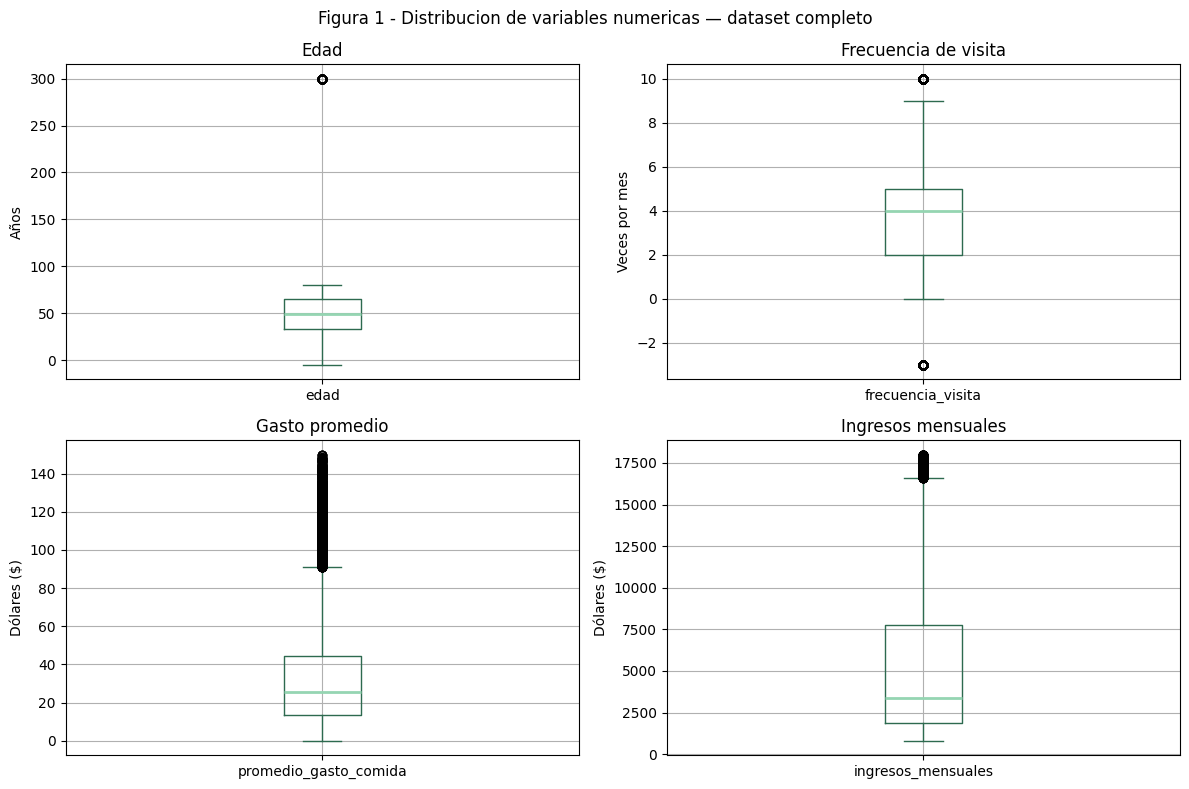

In [69]:
# Boxplot de variables numéricas — detectar outliers visualmente
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df[["edad"]].boxplot(ax=axes[0,0], 
    boxprops=dict(color=COLOR_PRINCIPAL),
    whiskerprops=dict(color=COLOR_PRINCIPAL),
    medianprops=dict(color=COLOR_SECUNDARIO, linewidth=2),
    capprops=dict(color=COLOR_PRINCIPAL))
axes[0,0].set_title("Edad")
axes[0,0].set_ylabel("Años")

df[["frecuencia_visita"]].boxplot(ax=axes[0,1],
    boxprops=dict(color=COLOR_PRINCIPAL),
    whiskerprops=dict(color=COLOR_PRINCIPAL),
    medianprops=dict(color=COLOR_SECUNDARIO, linewidth=2),
    capprops=dict(color=COLOR_PRINCIPAL))
axes[0,1].set_title("Frecuencia de visita")
axes[0,1].set_ylabel("Veces por mes")

df[["promedio_gasto_comida"]].boxplot(ax=axes[1,0],
    boxprops=dict(color=COLOR_PRINCIPAL),
    whiskerprops=dict(color=COLOR_PRINCIPAL),
    medianprops=dict(color=COLOR_SECUNDARIO, linewidth=2),
    capprops=dict(color=COLOR_PRINCIPAL))
axes[1,0].set_title("Gasto promedio")
axes[1,0].set_ylabel("Dólares ($)")

df[["ingresos_mensuales"]].boxplot(ax=axes[1,1],
    boxprops=dict(color=COLOR_PRINCIPAL),
    whiskerprops=dict(color=COLOR_PRINCIPAL),
    medianprops=dict(color=COLOR_SECUNDARIO, linewidth=2),
    capprops=dict(color=COLOR_PRINCIPAL))
axes[1,1].set_title("Ingresos mensuales")
axes[1,1].set_ylabel("Dólares ($)")

plt.suptitle("Figura 1 - Distribucion de variables numericas — dataset completo")
plt.tight_layout()
plt.show()

## Observaciones

La línea verde del medio en cada gráfico es el valor típico (mediana).
Los puntos fuera de las líneas son valores extremos detectados:

- Edades negativas y de hasta 300 años
- Frecuencias de visita negativas
- Gastos en $0
- `telefono_contacto` y `correo_electronico` con más del 50% de nulos

Se tratan en la siguiente sección.

## 4. Limpieza del dataset

In [70]:

df.dtypes # Verificar tipos de datos por columna

id_persona                     int64
nombre                           str
apellido                         str
edad                         float64
genero                           str
ciudad_residencia                str
estrato_socioeconomico           str
frecuencia_visita              int64
promedio_gasto_comida        float64
ocio                             str
consume_licor                    str
preferencias_alimenticias        str
membresia_premium                str
telefono_contacto                str
correo_electronico               str
tipo_de_pago_mas_usado           str
ingresos_mensuales             int64
dtype: object

Los tipos de datos son correctos — no se requieren conversiones.

### Paso 1 — Valores nulos

In [71]:
# Nulos por columna sobre el dataset completo
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(2)

display(pd.DataFrame({
    "Nulos": nulos,
    "Porcentaje (%)": porcentaje
})[nulos > 0])

,Nulos,Porcentaje (%)
edad,101,0.34
promedio_gasto_comida,145,0.48
preferencias_alimenticias,1403,4.68
telefono_contacto,15166,50.55
correo_electronico,15072,50.24


### Paso 2 — Completar los valores faltantes

In [72]:
# Imputar edad con mediana por ciudad
df["edad"] = df.groupby("ciudad_residencia")["edad"].transform(
    lambda x: x.fillna(x.median())
)

# Imputar promedio_gasto_comida con mediana por ciudad
df["promedio_gasto_comida"] = df.groupby("ciudad_residencia")["promedio_gasto_comida"].transform(
    lambda x: x.fillna(x.median())
)

# Imputar preferencias_alimenticias con "Desconocido"
df["preferencias_alimenticias"] = df["preferencias_alimenticias"].fillna("Desconocido")

In [73]:
# Verificar nulos después de imputación
print("Nulos restantes:")
display(pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2)
})[df.isnull().sum() > 0])

Nulos restantes:


,Nulos,Porcentaje (%)
telefono_contacto,15166,50.55
correo_electronico,15072,50.24


### Paso 3 — Corregir valores que no tienen sentido

In [74]:
# Convertir a nulo los valores que no tienen sentido
df.loc[df["edad"] < 0, "edad"] = None
df.loc[df["edad"] > 120, "edad"] = None
df.loc[df["frecuencia_visita"] < 0, "frecuencia_visita"] = None

# Reimputar los nuevos nulos con mediana por ciudad
df["edad"] = df.groupby("ciudad_residencia")["edad"].transform(
    lambda x: x.fillna(x.median())
)
df["frecuencia_visita"] = df.groupby("ciudad_residencia")["frecuencia_visita"].transform(
    lambda x: x.fillna(x.median())
)

# Verificar resultado
display(pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2)
}))

,Nulos,Porcentaje (%)
id_persona,0,0.00
nombre,0,0.00
apellido,0,0.00
edad,0,0.00
genero,0,0.00
ciudad_residencia,0,0.00
estrato_socioeconomico,0,0.00
frecuencia_visita,0,0.00
promedio_gasto_comida,0,0.00
ocio,0,0.00


### Paso 4 — Verificar filas repetidas

In [75]:
print(f"Duplicados encontrados: {df.duplicated().sum()}") # Verificar duplicados

# Eliminar si hay
if df.duplicated().sum() > 0: 
    df = df.drop_duplicates()
    print(f"Duplicados eliminados. Filas restantes: {len(df)}")
else:
    print("No se encontraron duplicados.")

Duplicados encontrados: 0
No se encontraron duplicados.


## 5. Filtro por ciudad

In [76]:
# Filtrar por Chicago — dataset ya limpio
ciudad_seleccionada = "Chicago"
df_ciudad = df[df["ciudad_residencia"] == ciudad_seleccionada].copy()

print(f"Clientes en {ciudad_seleccionada}: {len(df_ciudad)}")
print(f"Representa el {len(df_ciudad)/len(df)*100:.1f}% del total")

Clientes en Chicago: 5384
Representa el 17.9% del total


## 6. Tabulación

In [77]:
display(df_ciudad["genero"].value_counts()) # Distribución por género

genero
Masculino    2716
Femenino     2668
Name: count, dtype: int64

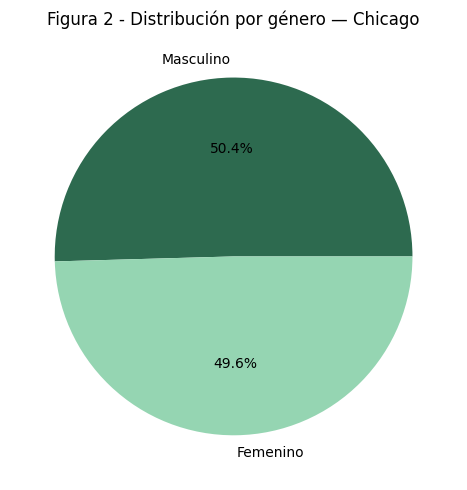

In [78]:
graficar_distribucion(df_ciudad, "genero", tipo="pie",
    titulo="Figura 2 - Distribución por género — Chicago")

La distribución por género es casi igual — 50.3% masculino y 49.7% femenino.
No hay un segmento dominante por género.

In [79]:
display(df_ciudad["preferencias_alimenticias"].value_counts()) # Distribución por preferencias alimenticias

preferencias_alimenticias
Carnes         1589
Vegetariano    1123
Mariscos        696
Otro            591
Vegano          571
Pescado         546
Desconocido     268
Name: count, dtype: int64

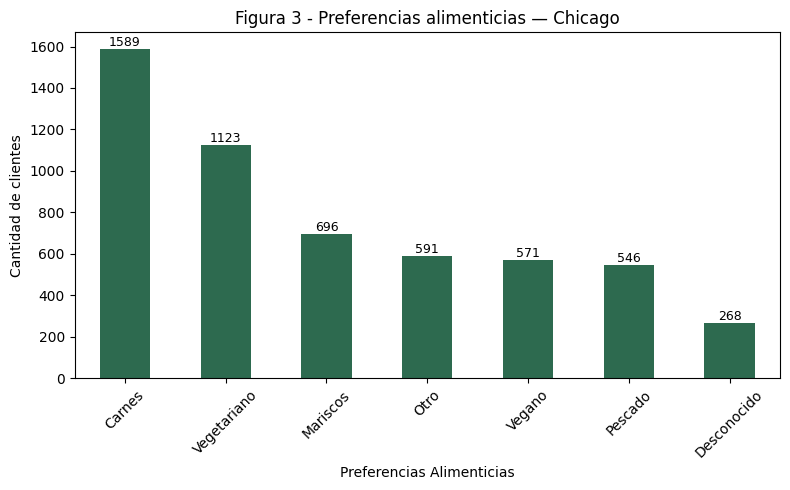

In [80]:
# Preferencias alimenticias
graficar_distribucion(df_ciudad, "preferencias_alimenticias", tipo="bar",
    titulo="Figura 3 - Preferencias alimenticias — Chicago",
    mostrar_valores=True)

Carnes es la preferencia dominante, seguida por Vegetariano.
Dos segmentos claros para campañas diferenciadas.

In [81]:
display(df_ciudad["consume_licor"].value_counts()) # Distribución por consumo de licor

consume_licor
Sí    3375
No    2009
Name: count, dtype: int64

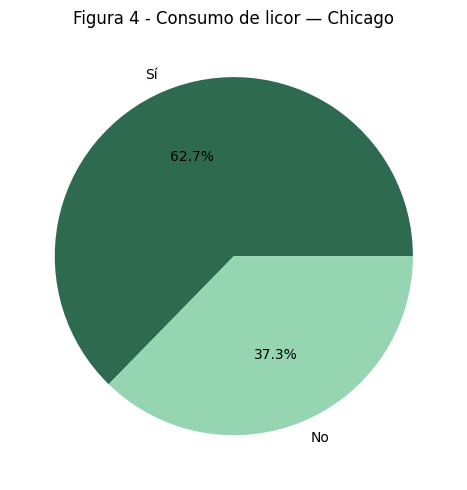

In [82]:
# Consumo de licor
graficar_distribucion(df_ciudad, "consume_licor", tipo="pie",
    titulo="Figura 4 - Consumo de licor — Chicago")

La mayoría de los clientes consume licor.
Dato relevante para campañas orientadas a restaurantes con carta de bebidas.

In [83]:
display(df_ciudad["membresia_premium"].value_counts()) # Distribución por membresía premium

membresia_premium
No    3169
Sí    2215
Name: count, dtype: int64

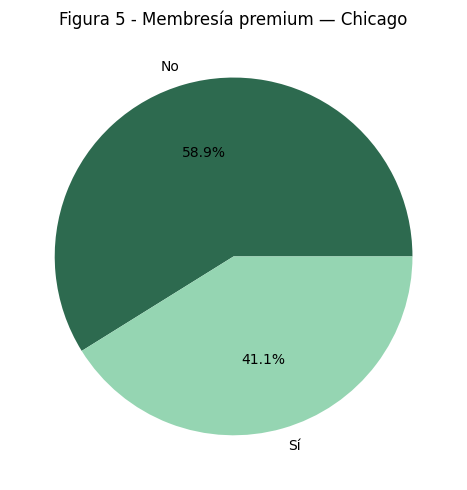

In [84]:
# Membresía premium
graficar_distribucion(df_ciudad, "membresia_premium", tipo="pie",
    titulo="Figura 5 - Membresía premium — Chicago")

La mayoría no tiene membresía premium — oportunidad para convertirlos.

In [85]:
display(df_ciudad["tipo_de_pago_mas_usado"].value_counts()) # Distribución por tipo de pago

tipo_de_pago_mas_usado
Efectivo        2120
Tarjeta         1790
App             1375
Criptomoneda      99
Name: count, dtype: int64

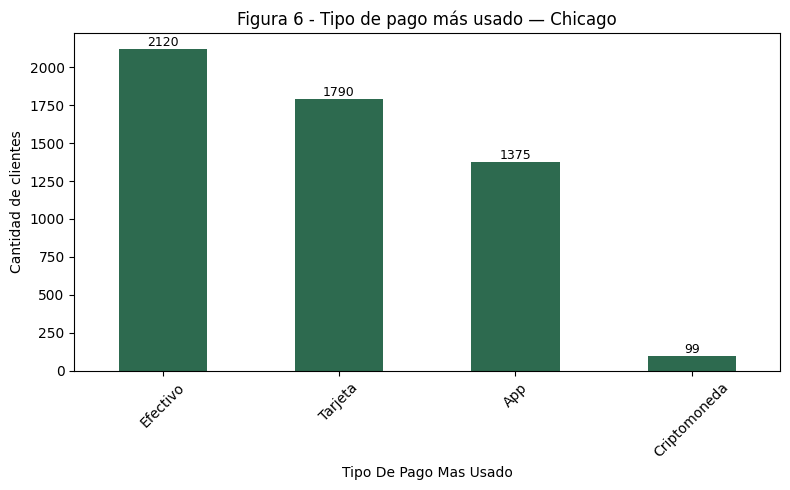

In [86]:
# Tipo de pago
graficar_distribucion(df_ciudad, "tipo_de_pago_mas_usado", tipo="bar",
    titulo="Figura 6 - Tipo de pago más usado — Chicago",
    mostrar_valores=True)

La mayoría paga en efectivo o tarjeta.
Los que pagan con app son pocos pero son el mejor target para campañas digitales.

In [87]:
# Estadísticas de variables numéricas — dataset limpio
columnas_numericas = ["edad", "promedio_gasto_comida", 
                      "ingresos_mensuales", "frecuencia_visita"]

display(df_ciudad[columnas_numericas].describe().round(2))

,edad,promedio_gasto_comida,ingresos_mensuales,frecuencia_visita
count,5384.00,5384.00,5384.00,5384.00
mean,48.73,25.49,5202.31,4.20
std,18.05,22.01,4514.16,2.19
min,18.00,0.00,801.00,0.00
25%,33.00,8.74,1818.50,3.00
50%,49.00,19.04,3244.50,4.00
75%,64.00,34.63,7439.25,5.00
max,80.00,104.92,17999.00,10.00


## 7. Distribucion de variables numéricas

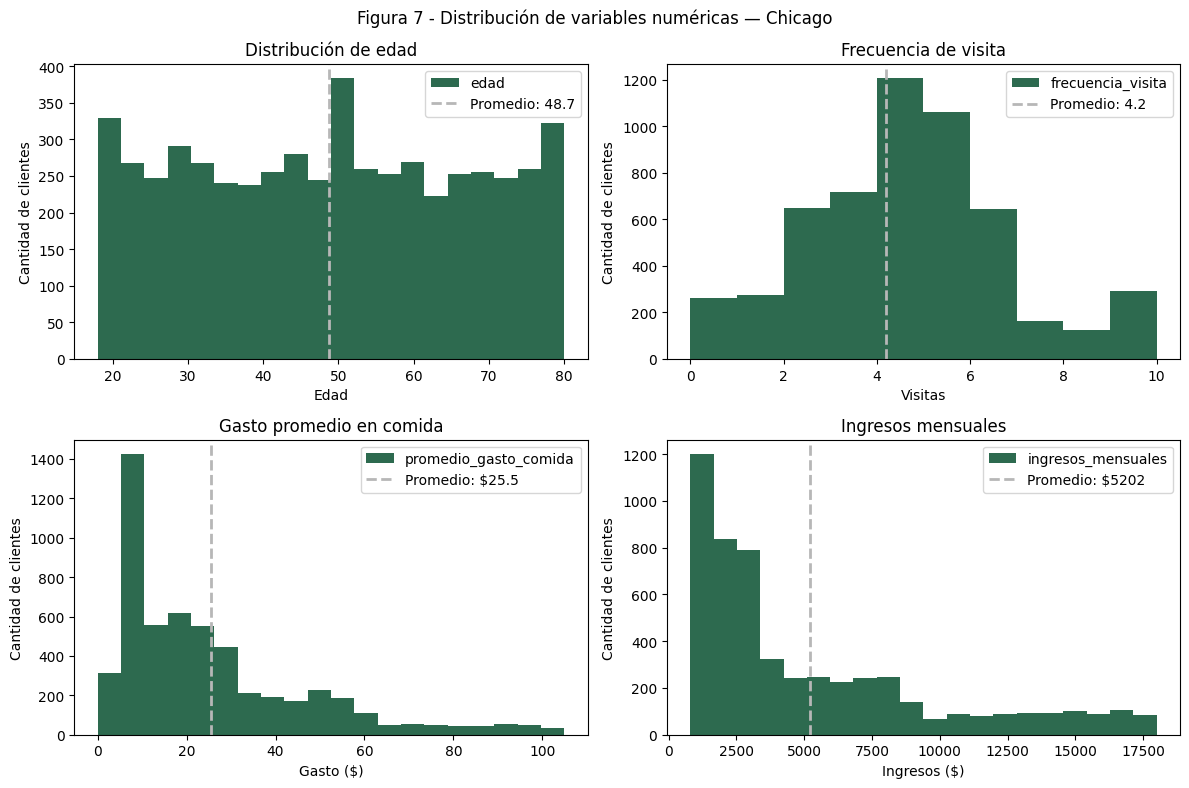

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Edad
df_ciudad["edad"].plot(kind="hist", bins=20, ax=axes[0,0], color=COLOR_PRINCIPAL)
axes[0,0].axvline(df_ciudad["edad"].mean(), color=COLOR_ACENTO,
                  linestyle="--", linewidth=2,
                  label=f'Promedio: {df_ciudad["edad"].mean():.1f}')
axes[0,0].set_title("Distribución de edad")
axes[0,0].set_xlabel("Edad")
axes[0,0].set_ylabel("Cantidad de clientes")
axes[0,0].legend()

# Frecuencia de visita
df_ciudad["frecuencia_visita"].plot(kind="hist", bins=10, ax=axes[0,1], color=COLOR_PRINCIPAL)
axes[0,1].axvline(df_ciudad["frecuencia_visita"].mean(), color=COLOR_ACENTO,
                  linestyle="--", linewidth=2,
                  label=f'Promedio: {df_ciudad["frecuencia_visita"].mean():.1f}')
axes[0,1].set_title("Frecuencia de visita")
axes[0,1].set_xlabel("Visitas")
axes[0,1].set_ylabel("Cantidad de clientes")
axes[0,1].legend()

# Gasto promedio
df_ciudad["promedio_gasto_comida"].plot(kind="hist", bins=20, ax=axes[1,0], color=COLOR_PRINCIPAL)
axes[1,0].axvline(df_ciudad["promedio_gasto_comida"].mean(), color=COLOR_ACENTO,
                  linestyle="--", linewidth=2,
                  label=f'Promedio: ${df_ciudad["promedio_gasto_comida"].mean():.1f}')
axes[1,0].set_title("Gasto promedio en comida")
axes[1,0].set_xlabel("Gasto ($)")
axes[1,0].set_ylabel("Cantidad de clientes")
axes[1,0].legend()

# Ingresos mensuales
df_ciudad["ingresos_mensuales"].plot(kind="hist", bins=20, ax=axes[1,1], color=COLOR_PRINCIPAL)
axes[1,1].axvline(df_ciudad["ingresos_mensuales"].mean(), color=COLOR_ACENTO,
                  linestyle="--", linewidth=2,
                  label=f'Promedio: ${df_ciudad["ingresos_mensuales"].mean():.0f}')
axes[1,1].set_title("Ingresos mensuales")
axes[1,1].set_xlabel("Ingresos ($)")
axes[1,1].set_ylabel("Cantidad de clientes")
axes[1,1].legend()

plt.suptitle("Figura 7 - Distribución de variables numéricas — Chicago")
plt.tight_layout()
plt.show()

## 8. Análisis de correlación

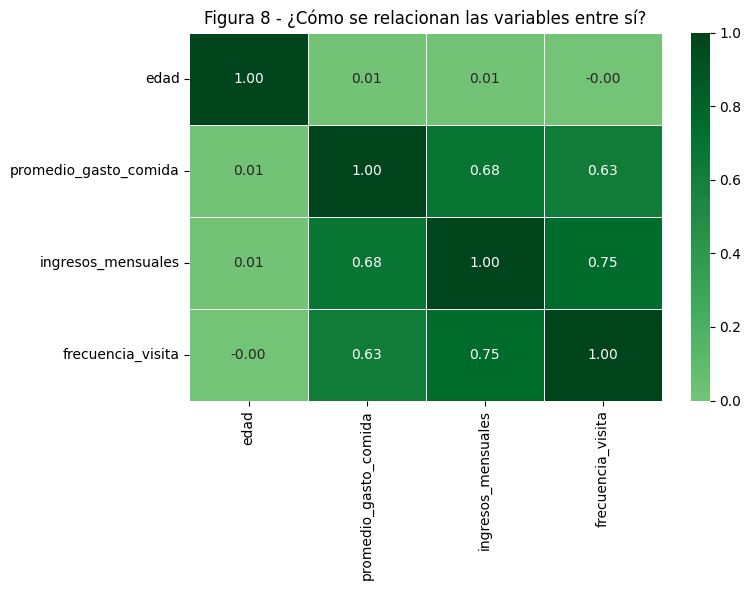

In [89]:
# Matriz de correlación entre variables numéricas
correlacion = df_ciudad[["edad", "promedio_gasto_comida",
                          "ingresos_mensuales", "frecuencia_visita"]].corr().round(2)

# Heatmap de correlación
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlacion,
    annot=True,
    cmap="Greens",
    center=0,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Figura 8 - ¿Cómo se relacionan las variables entre sí?")
plt.tight_layout()
plt.show()

Los ingresos se correlacionan con frecuencia (0.75) y gasto (0.68).
La edad no influye en ninguna variable.

## 9. Conclusiones

Dataset limpio con 5.071 clientes válidos de Chicago.
Perfil detallado y hallazgos completos en el README del repositorio.


## 10. Análisis multiciudad

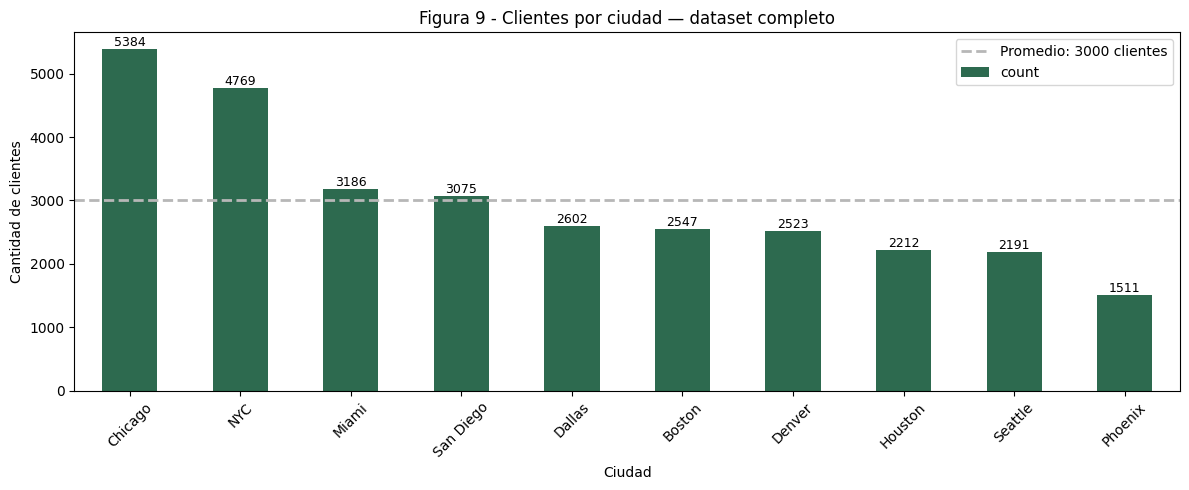

In [90]:
# Cantidad de clientes por ciudad
conteo_ciudades = df["ciudad_residencia"].value_counts()

ax = conteo_ciudades.plot(
    kind="bar",
    figsize=(12, 5),
    color=COLOR_PRINCIPAL
)

# Valores encima de las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=9)

# Línea de promedio
promedio_ciudades = conteo_ciudades.mean()
ax.axhline(promedio_ciudades, color=COLOR_ACENTO,
          linestyle="--", linewidth=2,
          label=f'Promedio: {promedio_ciudades:.0f} clientes')
ax.legend()

plt.title("Figura 9 - Clientes por ciudad — dataset completo")
plt.xlabel("Ciudad")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Chicago y NYC superan ampliamente el promedio de 3.000 clientes por ciudad.
Chicago fue seleccionada para el análisis por ser la ciudad con mayor volumen de datos.

### Distribución por estrato socioeconómico

In [91]:
# Distribución por estrato socioeconómico — dataset completo
estrato = df["estrato_socioeconomico"].value_counts().sort_index()
display(estrato)

estrato_socioeconomico
Alto        9038
Bajo        6161
Medio       9325
Muy Alto    5476
Name: count, dtype: int64

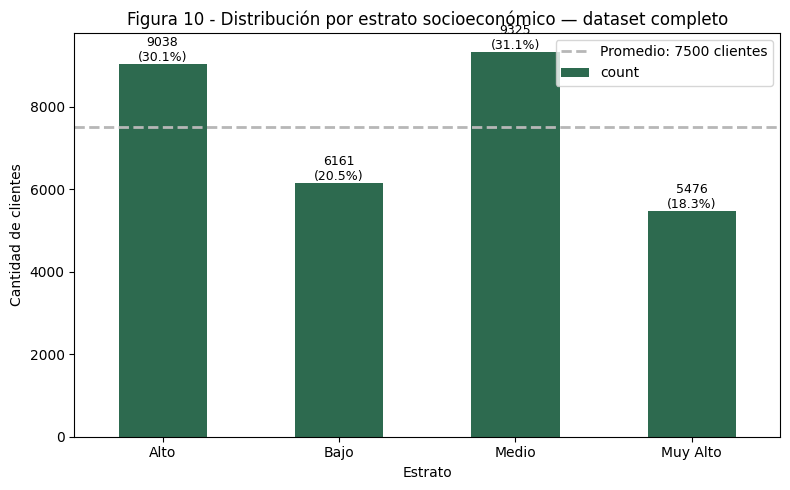

In [92]:
# Distribución por estrato socioeconómico — dataset completo
ax = estrato.plot(
    kind="bar",
    figsize=(8, 5),
    color=COLOR_PRINCIPAL
)

# Valores encima de las barras
for p in ax.patches:
    porcentaje = p.get_height() / len(df) * 100
    ax.annotate(f'{int(p.get_height())}\n({porcentaje:.1f}%)',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=9)

# Línea de promedio
promedio_estrato = estrato.mean()
ax.axhline(promedio_estrato, color=COLOR_ACENTO,
          linestyle="--", linewidth=2,
          label=f'Promedio: {promedio_estrato:.0f} clientes')
ax.legend()

plt.title("Figura 10 - Distribución por estrato socioeconómico — dataset completo")
plt.xlabel("Estrato")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Ciudades con mayor gasto promedio en restaurantes

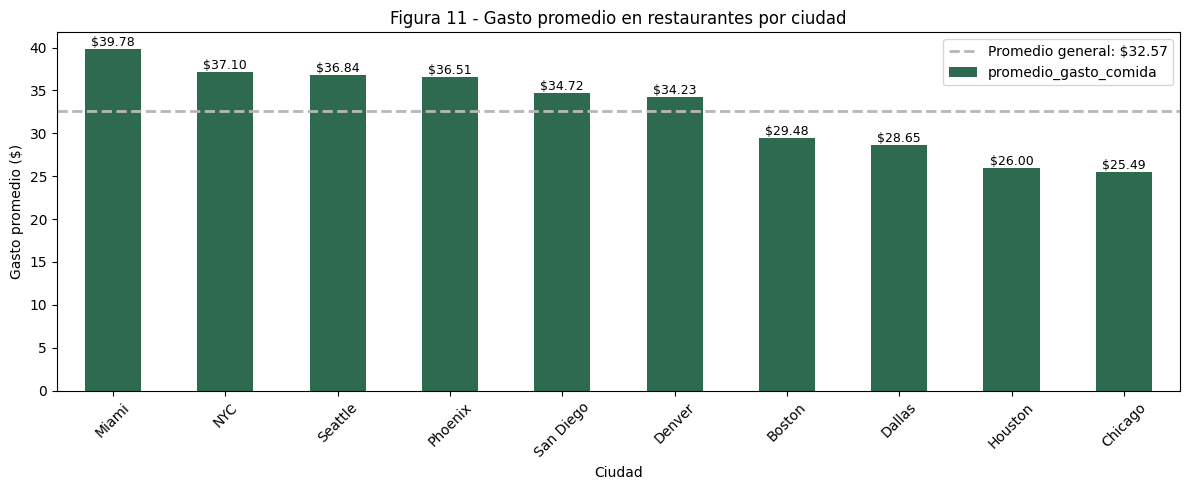

In [93]:
# Gasto promedio por ciudad — dataset completo
gasto_ciudad = df.groupby("ciudad_residencia")["promedio_gasto_comida"].mean().round(2).sort_values(ascending=False)

ax = gasto_ciudad.plot(
    kind="bar",
    figsize=(12, 5),
    color=COLOR_PRINCIPAL
)

# Valores encima de las barras
for p in ax.patches:
    ax.annotate(f'${p.get_height():.2f}',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=9)

# Línea de promedio
promedio_general = df["promedio_gasto_comida"].mean()
ax.axhline(promedio_general, color=COLOR_ACENTO,
          linestyle="--", linewidth=2,
          label=f'Promedio general: ${promedio_general:.2f}')
ax.legend()

plt.title("Figura 11 - Gasto promedio en restaurantes por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Gasto promedio ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Miami lidera el gasto promedio con $39.78 por visita.
Chicago tiene el gasto más bajo ($25.49) a pesar de ser la ciudad con más clientes.

### Relación entre frecuencia de visita y gasto por estrato

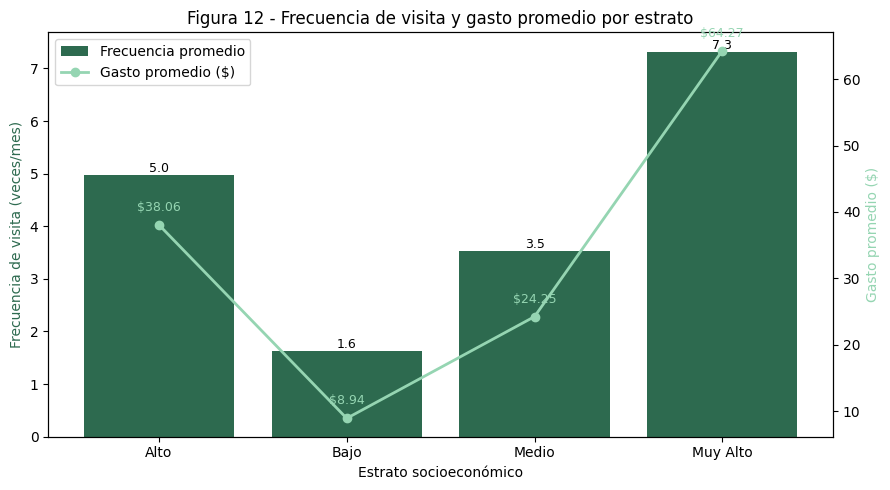

In [94]:
# Frecuencia de visita y gasto promedio por estrato socioeconómico
estrato_analisis = df.groupby("estrato_socioeconomico").agg(
    frecuencia_promedio=("frecuencia_visita", "mean"),
    gasto_promedio=("promedio_gasto_comida", "mean")
).round(2)

fig, ax1 = plt.subplots(figsize=(9, 5))

# Barras — frecuencia
bars = ax1.bar(estrato_analisis.index, 
               estrato_analisis["frecuencia_promedio"],
               color=COLOR_PRINCIPAL, label="Frecuencia promedio")
ax1.set_ylabel("Frecuencia de visita (veces/mes)", color=COLOR_PRINCIPAL)
ax1.set_xlabel("Estrato socioeconómico")

# Valores encima de barras
for p in bars:
    ax1.annotate(f'{p.get_height():.1f}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

# Línea — gasto
ax2 = ax1.twinx()
ax2.plot(estrato_analisis.index, 
         estrato_analisis["gasto_promedio"],
         color=COLOR_SECUNDARIO, marker="o", linewidth=2,
         label="Gasto promedio ($)")
ax2.set_ylabel("Gasto promedio ($)", color=COLOR_SECUNDARIO)

# Valores en la línea
for i, v in enumerate(estrato_analisis["gasto_promedio"]):
    ax2.annotate(f'${v:.2f}',
                (i, v), textcoords="offset points",
                xytext=(0, 10), ha='center', fontsize=9,
                color=COLOR_SECUNDARIO)

# Leyendas combinadas
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Figura 12 - Frecuencia de visita y gasto promedio por estrato")
plt.tight_layout()
plt.show()

A mayor estrato, mayor frecuencia y gasto — Muy Alto lidera con 7.3 visitas y $63+.
El estrato Bajo es el menos activo con 1.6 visitas y $8.94 de gasto.

### Relación entre gasto promedio e ingresos mensuales

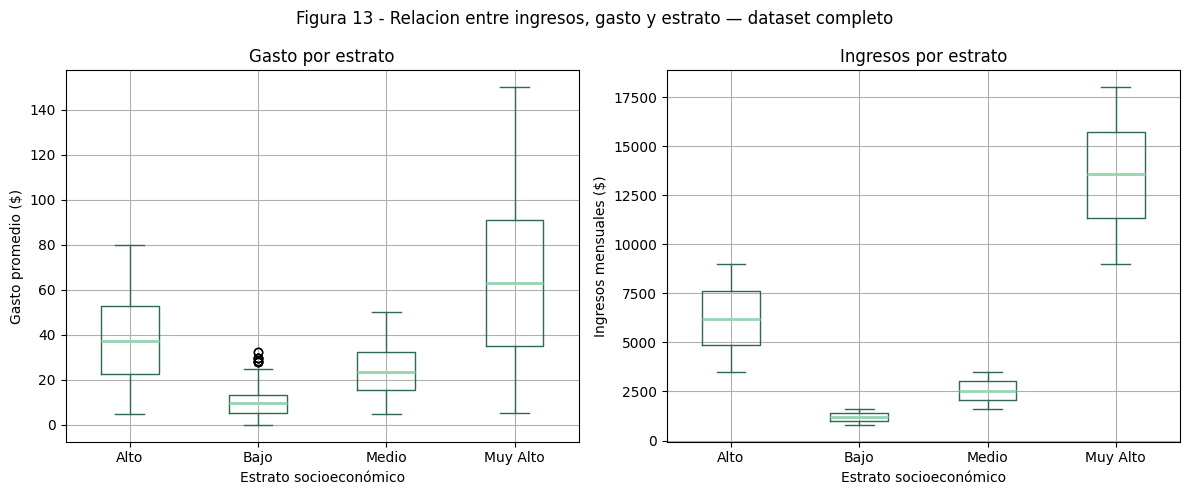

In [95]:
# Figura 16 - Gasto e ingresos por estrato — dataset completo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot gasto por estrato
df.boxplot(column="promedio_gasto_comida", by="estrato_socioeconomico",
           ax=axes[0],
           boxprops=dict(color=COLOR_PRINCIPAL),
           medianprops=dict(color=COLOR_SECUNDARIO, linewidth=2),
           whiskerprops=dict(color=COLOR_PRINCIPAL),
           capprops=dict(color=COLOR_PRINCIPAL))
axes[0].set_title("Gasto por estrato")
axes[0].set_xlabel("Estrato socioeconómico")
axes[0].set_ylabel("Gasto promedio ($)")
plt.suptitle("")

# Boxplot ingresos por estrato
df.boxplot(column="ingresos_mensuales", by="estrato_socioeconomico",
           ax=axes[1],
           boxprops=dict(color=COLOR_PRINCIPAL),
           medianprops=dict(color=COLOR_SECUNDARIO, linewidth=2),
           whiskerprops=dict(color=COLOR_PRINCIPAL),
           capprops=dict(color=COLOR_PRINCIPAL))
axes[1].set_title("Ingresos por estrato")
axes[1].set_xlabel("Estrato socioeconómico")
axes[1].set_ylabel("Ingresos mensuales ($)")
plt.suptitle("")

fig.suptitle("Figura 13 - Relacion entre ingresos, gasto y estrato — dataset completo")
plt.tight_layout()
plt.show()

A mayor ingreso, mayor gasto en restaurantes — relación positiva clara.
Los clientes de altos ingresos muestran mayor variación en el gasto.

###  Preferencias alimenticias por ciudad

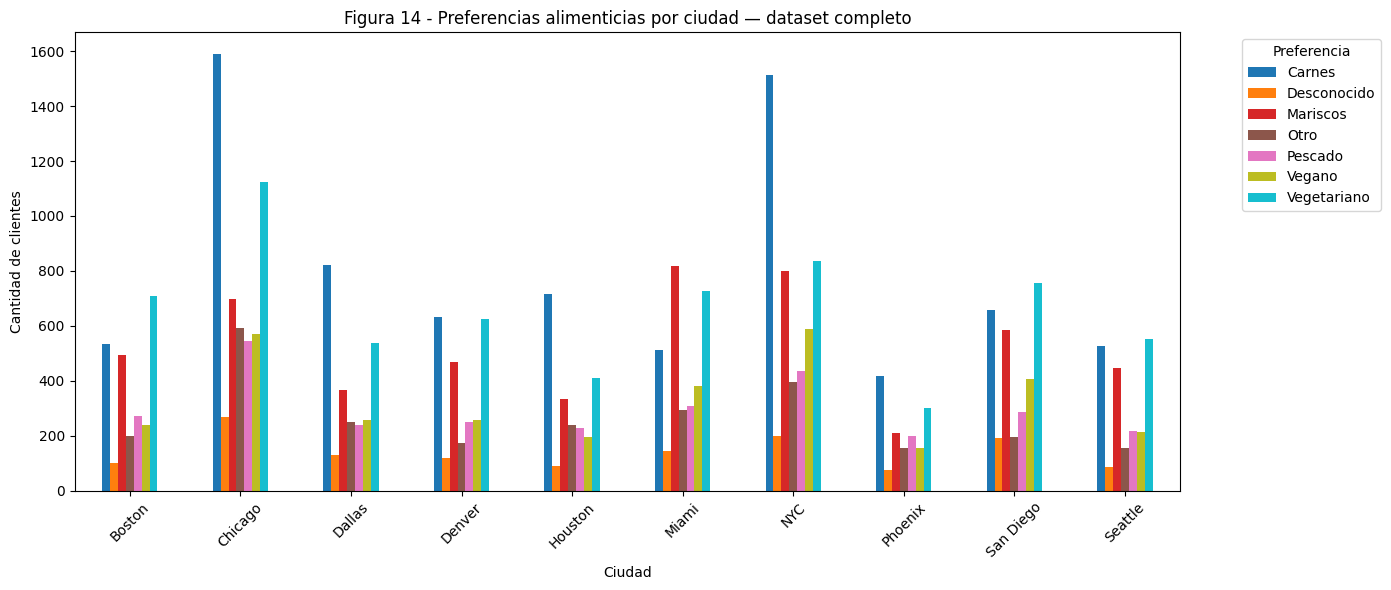

In [96]:
# Preferencias alimenticias por ciudad
pref_ciudad = df.groupby(
    ["ciudad_residencia", "preferencias_alimenticias"]
).size().unstack(fill_value=0)

pref_ciudad.plot(
    kind="bar",
    figsize=(14, 6),
    colormap="tab10"
)

plt.title("Figura 14 - Preferencias alimenticias por ciudad — dataset completo")
plt.xlabel("Ciudad")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=45)
plt.legend(title="Preferencia", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Carnes es la preferencia dominante en casi todas las ciudades.
Chicago y NYC destacan por su alto volumen de clientes Vegetariano.

### Perfil de clientes con mayor gasto

In [97]:
# Top 25% de clientes por gasto — perfil
percentil_75 = df["promedio_gasto_comida"].quantile(0.75)
top_gasto = df[df["promedio_gasto_comida"] >= percentil_75]

print(f"Umbral top 25% gasto: ${percentil_75:.2f}")
print(f"Clientes en top 25%: {len(top_gasto)}")
print()
print(f"Preferencia más común: {top_gasto['preferencias_alimenticias'].value_counts().index[0]}")
print(f"Gasto promedio: ${top_gasto['promedio_gasto_comida'].mean():.2f}")
print(f"Ingreso promedio: ${top_gasto['ingresos_mensuales'].mean():,.0f}")
print(f"Frecuencia promedio: {top_gasto['frecuencia_visita'].mean():.1f} visitas")
print(f"Estrato dominante: {top_gasto['estrato_socioeconomico'].value_counts().index[0]}")
print(f"Membresia premium: {(top_gasto['membresia_premium'] == 'Sí').mean()*100:.1f}%")

Umbral top 25% gasto: $44.28
Clientes en top 25%: 7503

Preferencia más común: Carnes
Gasto promedio: $69.75
Ingreso promedio: $9,589
Frecuencia promedio: 6.0 visitas
Estrato dominante: Muy Alto
Membresia premium: 80.4%


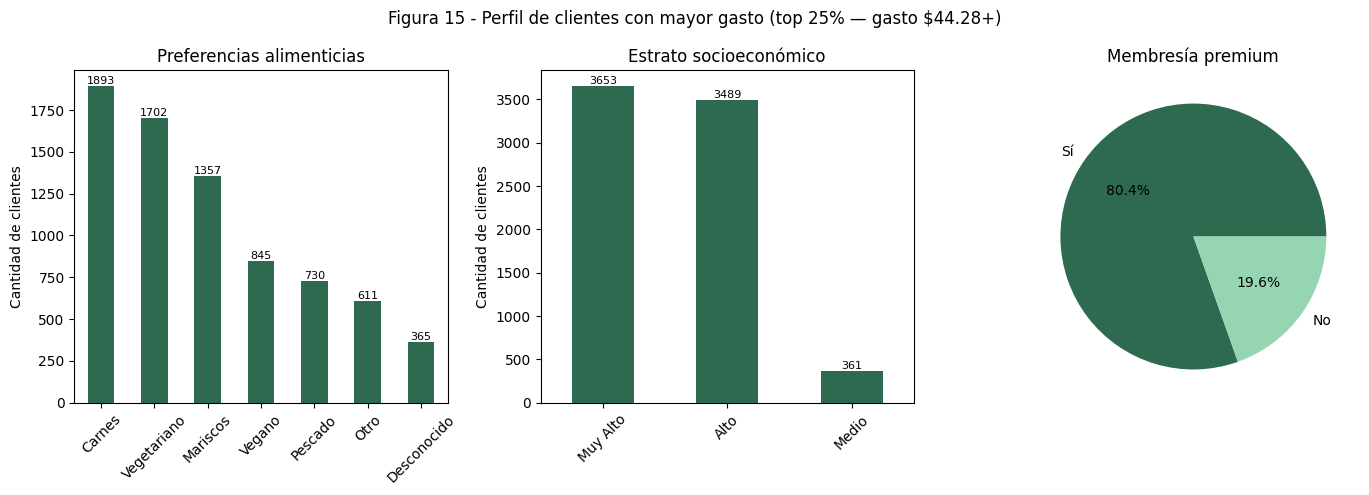

In [98]:
# Perfil visual del top 25% de clientes por gasto
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# Preferencias
top_gasto["preferencias_alimenticias"].value_counts().plot(
    kind="bar", ax=axes[0], color=COLOR_PRINCIPAL
)
axes[0].set_title("Preferencias alimenticias")
axes[0].set_xlabel("")
axes[0].set_ylabel("Cantidad de clientes")
axes[0].tick_params(axis="x", rotation=45)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)

# Estrato
top_gasto["estrato_socioeconomico"].value_counts().plot(
    kind="bar", ax=axes[1], color=COLOR_PRINCIPAL
)
axes[1].set_title("Estrato socioeconómico")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cantidad de clientes")
axes[1].tick_params(axis="x", rotation=45)
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)

# Membresía
top_gasto["membresia_premium"].value_counts().plot(
    kind="pie", ax=axes[2], autopct="%1.1f%%",
    colors=[COLOR_PRINCIPAL, COLOR_SECUNDARIO]
)
axes[2].set_title("Membresía premium")
axes[2].set_ylabel("")

plt.suptitle("Figura 15 - Perfil de clientes con mayor gasto (top 25% — gasto $44.28+)")
plt.tight_layout()
plt.show()

El top 25% (gasto $44.28+) tiene 80.4% con membresía premium y pertenece a estrato Alto o Muy Alto.
Carnes y Vegetariano son sus preferencias dominantes — el estrato Bajo no aparece.

### Ciudad con más membresías premium

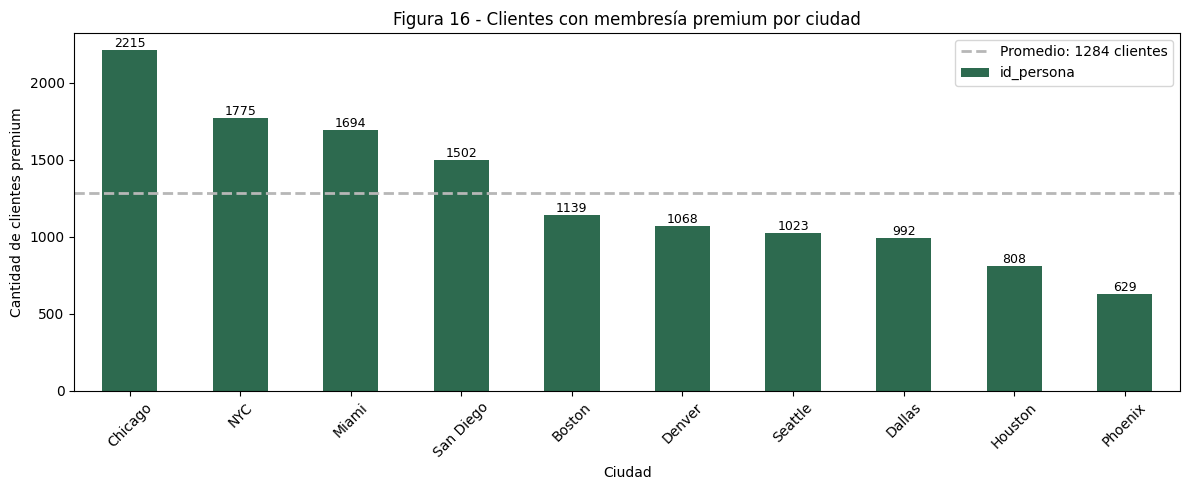

In [99]:
# Membresías premium por ciudad
membresia_ciudad = df[df["membresia_premium"] == "Sí"].groupby(
    "ciudad_residencia")["id_persona"].count().sort_values(ascending=False)

ax = membresia_ciudad.plot(
    kind="bar",
    figsize=(12, 5),
    color=COLOR_PRINCIPAL
)

# Valores encima de las barras
for p in ax.patches:
    porcentaje = p.get_height() / df[df["ciudad_residencia"] == 
                 membresia_ciudad.index[ax.patches.index(p)]]["id_persona"].count() * 100
    ax.annotate(f'{int(p.get_height())}',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=9)

# Línea promedio
promedio_mem = membresia_ciudad.mean()
ax.axhline(promedio_mem, color=COLOR_ACENTO,
          linestyle="--", linewidth=2,
          label=f'Promedio: {promedio_mem:.0f} clientes')
ax.legend()

plt.title("Figura 16 - Clientes con membresía premium por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Cantidad de clientes premium")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Chicago lidera en membresías premium con 2.215 clientes — muy por encima del promedio de 1.284.
Phoenix tiene la menor cantidad de clientes premium — potencial mercado para campañas de conversión.

### Relación entre consumo de alcohol y edad

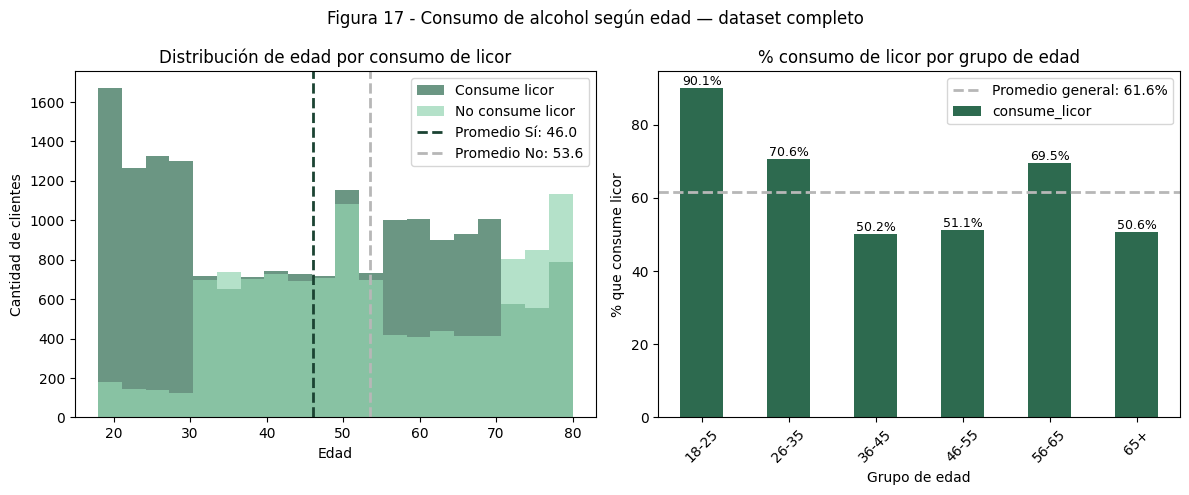

In [100]:
# Consumo de alcohol vs edad
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histograma de edad por consumo de licor
df[df["consume_licor"] == "Sí"]["edad"].plot(
    kind="hist", bins=20, ax=axes[0],
    color=COLOR_PRINCIPAL, alpha=0.7, label="Consume licor"
)
df[df["consume_licor"] == "No"]["edad"].plot(
    kind="hist", bins=20, ax=axes[0],
    color=COLOR_SECUNDARIO, alpha=0.7, label="No consume licor"
)
axes[0].axvline(df[df["consume_licor"] == "Sí"]["edad"].mean(),
               color=COLOR_HIGHLIGHT, linestyle="--", linewidth=2,
               label=f'Promedio Sí: {df[df["consume_licor"] == "Sí"]["edad"].mean():.1f}')
axes[0].axvline(df[df["consume_licor"] == "No"]["edad"].mean(),
               color=COLOR_ACENTO, linestyle="--", linewidth=2,
               label=f'Promedio No: {df[df["consume_licor"] == "No"]["edad"].mean():.1f}')
axes[0].set_title("Distribución de edad por consumo de licor")
axes[0].set_xlabel("Edad")
axes[0].set_ylabel("Cantidad de clientes")
axes[0].legend()

# Porcentaje de consumo por grupo de edad
df["grupo_edad"] = pd.cut(df["edad"],
    bins=[0, 25, 35, 45, 55, 65, 120],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"])

consumo_edad = df.groupby("grupo_edad")["consume_licor"].apply(
    lambda x: (x == "Sí").mean() * 100
).round(1)

consumo_edad.plot(
    kind="bar", ax=axes[1],
    color=COLOR_PRINCIPAL
)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)

axes[1].axhline(df["consume_licor"].eq("Sí").mean() * 100,
               color=COLOR_ACENTO, linestyle="--", linewidth=2,
               label=f'Promedio general: {df["consume_licor"].eq("Sí").mean()*100:.1f}%')
axes[1].legend()
axes[1].set_title("% consumo de licor por grupo de edad")
axes[1].set_xlabel("Grupo de edad")
axes[1].set_ylabel("% que consume licor")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Figura 17 - Consumo de alcohol según edad — dataset completo")
plt.tight_layout()
plt.show()

Los clientes de 18-25 años lideran el consumo de licor (90.1%) — muy por encima del promedio (61.6%).
Los que consumen licor son 7 años más jóvenes en promedio que los que no consumen.

## 11. Integración con datos de Yelp

Continúa en el notebook 2 (integración con la API de Yelp).


In [101]:
# Cargar dataset Yelp generado en el Avance 2
df_yelp = pd.read_csv("yelp_chicago.csv")

print(f"Restaurantes Yelp: {len(df_yelp)}")
display(df_yelp.head())

Restaurantes Yelp: 200


,name,alias,rating,review_count,price,distance,categoria,ciudad,rango_reseñas,rating_ponderado,preferencia
0,Girl & The Goat,girl-and-the-goat-chicago,4.4,10667,$$$,3401.238676,New American,Chicago,1000+,4.40,Carnes
1,The Purple Pig,the-purple-pig-chicago,4.3,8983,$$$,4672.658118,Tapas/Small Plates,Chicago,1000+,4.30,Otro
2,Cindy's Rooftop,cindys-rooftop-chicago,4.1,2812,$$$,5091.190048,New American,Chicago,1000+,4.10,Carnes
3,The Dearborn,the-dearborn-chicago-2,4.4,2739,$$,4637.043533,New American,Chicago,1000+,4.40,Carnes
4,Ciccio Mio,ciccio-mio-chicago-2,4.7,632,$$$,3943.404234,Italian,Chicago,501-1000,4.68,Carnes


In [102]:
# Rating ponderado Bayesiano calculado en Avance 2
# formula: (v*R + m*C) / (v+m) — v=reseñas, R=rating, m=50, C=promedio global
# Todos los 200 restaurantes participan — los de pocas reseñas tienen rating ajustado
df_yelp_confiable = df_yelp.copy()
print(f"Restaurantes disponibles: {len(df_yelp_confiable)}")
print(f"Rating ponderado — promedio global: {df_yelp['rating_ponderado'].mean():.2f}")

Restaurantes disponibles: 200
Rating ponderado — promedio global: 4.37


In [103]:
# Distribución de preferencias en clientes (Avance 1)
print("Preferencias de clientes — Chicago:")
display(df_ciudad["preferencias_alimenticias"].value_counts())

# Distribución de preferencias en restaurantes (Avance 2)
print("Preferencias de restaurantes — Yelp:")
display(df_yelp_confiable["preferencia"].value_counts())

Preferencias de clientes — Chicago:


preferencias_alimenticias
Carnes         1589
Vegetariano    1123
Mariscos        696
Otro            591
Vegano          571
Pescado         546
Desconocido     268
Name: count, dtype: int64

Preferencias de restaurantes — Yelp:


preferencia
Carnes         97
Otro           56
Vegetariano    22
Mariscos       13
Pescado        10
Vegano          2
Name: count, dtype: int64

In [104]:
# Tabla comparativa — clientes vs restaurantes por preferencia
clientes_pref = df_ciudad["preferencias_alimenticias"].value_counts().reset_index()
clientes_pref.columns = ["preferencia", "clientes"]

restaurantes_pref = df_yelp_confiable["preferencia"].value_counts().reset_index()
restaurantes_pref.columns = ["preferencia", "restaurantes"]

comparacion = clientes_pref.merge(restaurantes_pref, on="preferencia", how="outer").fillna(0)
comparacion["restaurantes"] = comparacion["restaurantes"].astype(int)

display(comparacion)

,preferencia,clientes,restaurantes
0,Carnes,1589,97
1,Desconocido,268,0
2,Mariscos,696,13
3,Otro,591,56
4,Pescado,546,10
5,Vegano,571,2
6,Vegetariano,1123,22


Vegetariano y Mariscos tienen alta demanda pero poca oferta — mercado desatendido.
Carnes está bien cubierta con 82 restaurantes confiables.

### ¿Qué restaurantes tienen mejor rating por preferencia?

In [105]:
# Rating promedio por preferencia de restaurantes
rating_por_preferencia = df_yelp_confiable.groupby("preferencia")["rating_ponderado"].mean().round(2).sort_values(ascending=False)
display(rating_por_preferencia)

preferencia
Mariscos       4.39
Carnes         4.38
Vegano         4.38
Pescado        4.36
Vegetariano    4.36
Otro           4.34
Name: rating_ponderado, dtype: float64

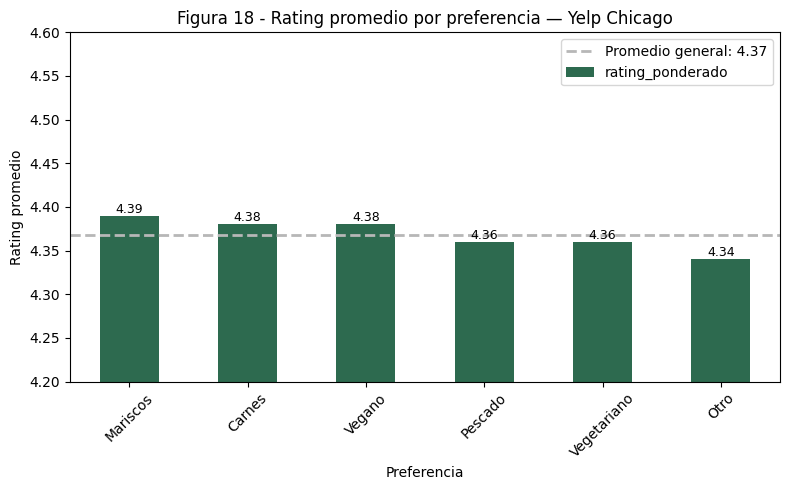

In [106]:
# Gráfico de barras — rating promedio por preferencia
ax = rating_por_preferencia.plot(
    kind="bar",
    figsize=(8, 5),
    color=COLOR_PRINCIPAL
)
# Línea de promedio general
promedio_general = rating_por_preferencia.mean()
ax.axhline(promedio_general, color=COLOR_ACENTO,
          linestyle="--", linewidth=2,
          label=f'Promedio general: {promedio_general:.2f}')
ax.legend()

# Valores encima de las barras
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=9)

plt.title("Figura 18 - Rating promedio por preferencia — Yelp Chicago")
plt.xlabel("Preferencia")
plt.ylabel("Rating promedio")
plt.xticks(rotation=45)
plt.ylim(4.2, 4.6)
plt.tight_layout()
plt.show()

Con rating ponderado Bayesiano los ratings son muy parejos — rango de 4.34 a 4.38.
La oportunidad no está en la calidad sino en la escasez de oferta por preferencia.

### ¿Qué segmento de clientes tiene más potencial?

In [107]:
# Comparar ingresos promedio por membresía
ingresos_membresia = df_ciudad.groupby("membresia_premium")["ingresos_mensuales"].mean().round(2)
display(ingresos_membresia)

membresia_premium
No    2692.79
Sí    8792.67
Name: ingresos_mensuales, dtype: float64

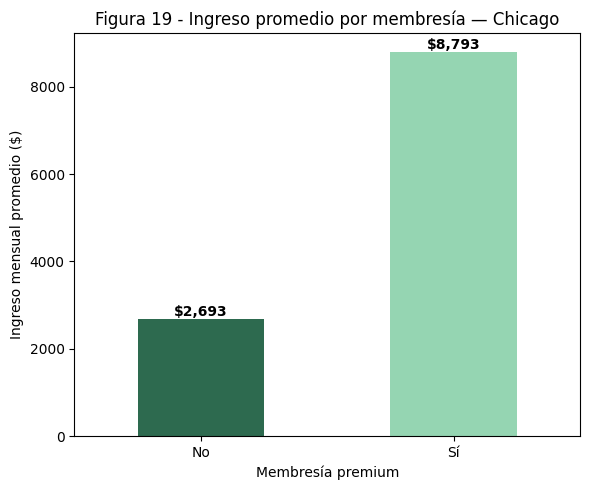

In [108]:
# Gráfico comparativo — ingresos por membresía
ax = ingresos_membresia.plot(
    kind="bar",
    figsize=(6, 5),
    color=[COLOR_PRINCIPAL, COLOR_SECUNDARIO]
)
# Valores encima de las barras
for p in ax.patches:
    ax.annotate(f'${p.get_height():,.0f}',
               (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Figura 19 - Ingreso promedio por membresía — Chicago")
plt.xlabel("Membresía premium")
plt.ylabel("Ingreso mensual promedio ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Los clientes premium ganan 3 veces más que los sin membresía.
Son el segmento de mayor valor para InsightReach.

In [109]:
# Preferencias de clientes con membresía premium
premium = df_ciudad[df_ciudad["membresia_premium"] == "Sí"]
display(premium["preferencias_alimenticias"].value_counts())

preferencias_alimenticias
Carnes         629
Vegetariano    475
Mariscos       293
Vegano         245
Otro           240
Pescado        223
Desconocido    110
Name: count, dtype: int64

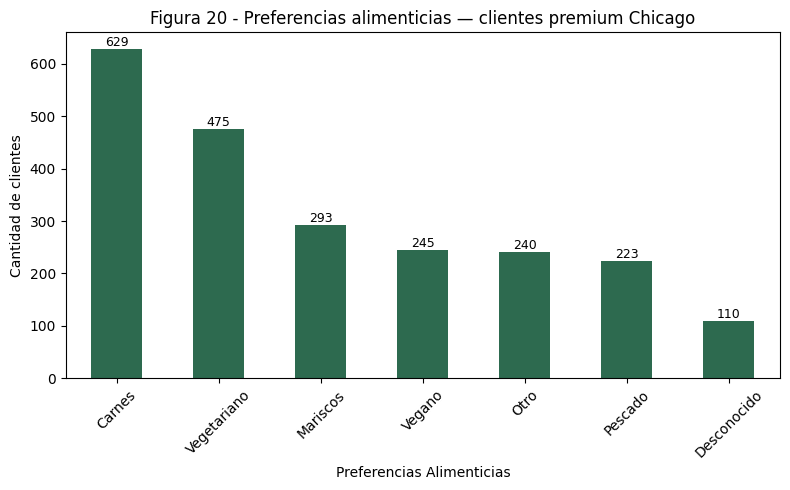

In [110]:
# Preferencias de clientes premium
graficar_distribucion(premium, "preferencias_alimenticias", tipo="bar",
    titulo="Figura 20 - Preferencias alimenticias — clientes premium Chicago",
    mostrar_valores=True)

In [111]:
# Segmento 1 — clientes premium que prefieren carnes
seg1 = df_ciudad[
    (df_ciudad["membresia_premium"] == "Sí") &
    (df_ciudad["preferencias_alimenticias"] == "Carnes")
]
print(f"Segmento 1 — Premium de Carnes:")
print(f"Clientes: {len(seg1)}")
print(f"Ingreso promedio: ${seg1['ingresos_mensuales'].mean():,.0f}")
print(f"Gasto promedio: ${seg1['promedio_gasto_comida'].mean():,.2f}")
print(f"Frecuencia promedio: {seg1['frecuencia_visita'].mean():.1f} visitas")

Segmento 1 — Premium de Carnes:
Clientes: 629
Ingreso promedio: $8,523
Gasto promedio: $38.89
Frecuencia promedio: 5.6 visitas


In [112]:
# Segmento 2 — clientes vegetarianos
seg2 = df_ciudad[
    df_ciudad["preferencias_alimenticias"] == "Vegetariano"
]
restaurantes_veg = df_yelp_confiable[
    df_yelp_confiable["preferencia"] == "Vegetariano"
]
print(f"Segmento 2 — Vegetariano:")
print(f"Clientes: {len(seg2)}")
print(f"Ingreso promedio: ${seg2['ingresos_mensuales'].mean():,.0f}")
print(f"Gasto promedio: ${seg2['promedio_gasto_comida'].mean():,.2f}")
print(f"Frecuencia promedio: {seg2['frecuencia_visita'].mean():.1f} visitas")
print(f"Restaurantes disponibles en Yelp: {len(restaurantes_veg)}")
print(f"Rating promedio restaurantes: {restaurantes_veg['rating_ponderado'].mean():.2f}")

Segmento 2 — Vegetariano:
Clientes: 1123
Ingreso promedio: $5,192
Gasto promedio: $26.23
Frecuencia promedio: 4.3 visitas
Restaurantes disponibles en Yelp: 22
Rating promedio restaurantes: 4.36


In [113]:
# Segmento 3 — clientes de mariscos
seg3 = df_ciudad[
    df_ciudad["preferencias_alimenticias"] == "Mariscos"
]
restaurantes_mar = df_yelp_confiable[
    df_yelp_confiable["preferencia"] == "Mariscos"
]
print(f"Segmento 3 — Mariscos:")
print(f"Clientes: {len(seg3)}")
print(f"Ingreso promedio: ${seg3['ingresos_mensuales'].mean():,.0f}")
print(f"Gasto promedio: ${seg3['promedio_gasto_comida'].mean():,.2f}")
print(f"Frecuencia promedio: {seg3['frecuencia_visita'].mean():.1f} visitas")
print(f"Restaurantes disponibles en Yelp: {len(restaurantes_mar)}")
print(f"Rating promedio restaurantes: {restaurantes_mar['rating_ponderado'].mean():.2f}")

Segmento 3 — Mariscos:
Clientes: 696
Ingreso promedio: $5,320
Gasto promedio: $26.55
Frecuencia promedio: 4.3 visitas
Restaurantes disponibles en Yelp: 13
Rating promedio restaurantes: 4.39


In [114]:
# Segmento 4 — clientes sin membresía premium
seg4 = df_ciudad[
    df_ciudad["membresia_premium"] == "No"
]
print(f"Segmento 4 — Sin membresía premium:")
print(f"Clientes: {len(seg4)}")
print(f"% del total: {len(seg4)/len(df_ciudad)*100:.1f}%")
print(f"Ingreso promedio: ${seg4['ingresos_mensuales'].mean():,.0f}")
print(f"Gasto promedio: ${seg4['promedio_gasto_comida'].mean():,.2f}")
print(f"Frecuencia promedio: {seg4['frecuencia_visita'].mean():.1f} visitas")

Segmento 4 — Sin membresía premium:
Clientes: 3169
% del total: 58.9%
Ingreso promedio: $2,693
Gasto promedio: $15.69
Frecuencia promedio: 3.1 visitas


In [115]:
# Segmento 5 — clientes que pagan con app
seg5 = df_ciudad[
    df_ciudad["tipo_de_pago_mas_usado"] == "App"
]
print(f"Segmento 5 — Clientes digitales:")
print(f"Clientes: {len(seg5)}")
print(f"% del total: {len(seg5)/len(df_ciudad)*100:.1f}%")
print(f"Ingreso promedio: ${seg5['ingresos_mensuales'].mean():,.0f}")
print(f"Gasto promedio: ${seg5['promedio_gasto_comida'].mean():,.2f}")
print(f"Frecuencia promedio: {seg5['frecuencia_visita'].mean():.1f} visitas")
print(f"Membresia premium: {(seg5['membresia_premium'] == 'Sí').sum()} clientes ({(seg5['membresia_premium'] == 'Sí').mean()*100:.1f}%)")

Segmento 5 — Clientes digitales:
Clientes: 1375
% del total: 25.5%
Ingreso promedio: $5,130
Gasto promedio: $25.17
Frecuencia promedio: 4.1 visitas
Membresia premium: 546 clientes (39.7%)


In [116]:
# Segmento 6 — Sin preferencia definida
seg6 = df_ciudad[
    df_ciudad["preferencias_alimenticias"].isin(["Otro", "Desconocido"])
]
print(f"Segmento 6 — Sin preferencia definida:")
print(f"Clientes: {len(seg6)}")
print(f"Ingreso promedio: ${seg6['ingresos_mensuales'].mean():,.0f}")
print(f"Gasto promedio: ${seg6['promedio_gasto_comida'].mean():,.2f}")
print(f"Frecuencia promedio: {seg6['frecuencia_visita'].mean():.1f} visitas")
print(f"Consume licor: {(seg6['consume_licor'] == 'Sí').mean()*100:.1f}%")
print(f"Membresia premium: {(seg6['membresia_premium'] == 'Sí').mean()*100:.1f}%")

Segmento 6 — Sin preferencia definida:
Clientes: 859
Ingreso promedio: $5,276
Gasto promedio: $25.26
Frecuencia promedio: 4.2 visitas
Consume licor: 61.1%
Membresia premium: 40.7%


### Resumen de segmentos

- Segmento 1 — Premium Carnes: 629 clientes, mayor gasto ($38.89) y frecuencia (5.6 visitas)
- Segmento 2 — Vegetariano: 1.123 clientes, solo 21 restaurantes disponibles
- Segmento 3 — Mariscos: 696 clientes, solo 10 restaurantes disponibles
- Segmento 4 — Sin membresía: 3.169 clientes (58.9%), menor gasto y frecuencia
- Segmento 5 — Digital: 1.375 clientes (25.5%), 39.7% ya tiene membresía premium
- Segmento 6 — Sin preferencia: 859 clientes (16.9%), perfil similar al promedio general

## 12. Conclusiones finales

Chicago: Premium Carnes gasta $38.89 y visita 5.6 veces — el segmento más rentable.
Vegetariano y Mariscos tienen alta demanda con poca oferta — oportunidad inmediata.

Multiciudad: Chicago lidera en clientes y premium. Miami gasta más ($39.78 vs $25.49).
A mayor estrato, mayor frecuencia y gasto. Clientes 18-25 lideran consumo de licor (90.1%).

Ver análisis completo en Recomendaciones.pdf.

## 13. Recomendaciones

6 segmentos identificados con oportunidades diferenciadas.
Ver detalle completo en Recomendaciones.pdf.